## 1. Import Libraries

In [ ]:
import os
import copy
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from tqdm.notebook import tqdm

## 3. Dataset and Image Preprocessing


In [ ]:
dataset_path = "./data"

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.CIFAR10(
    root=dataset_path, train=True, download=True, transform=train_transform
)

val_dataset = datasets.CIFAR10(
    root=dataset_path, train=True, download=True, transform=test_transform
)

test_dataset = datasets.CIFAR10(
    root=dataset_path, train=False, download=True, transform=test_transform
)

class_names = train_dataset.classes

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Test images: 10000


## 4. Train and Validation Split


In [ ]:
indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.1,
    random_state=42,
    stratify=labels
)

train_data = Subset(train_dataset, train_indices)
val_data = Subset(val_dataset, val_indices)

print("Train samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Test samples:", len(test_dataset))

Train samples: 45000
Validation samples: 5000
Test samples: 10000


## 5. Create DataLoaders

In [ ]:
BATCH_SIZE = 64
NUM_WORKERS = 2

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully")

DataLoaders created successfully


## 6. Display Sample Images

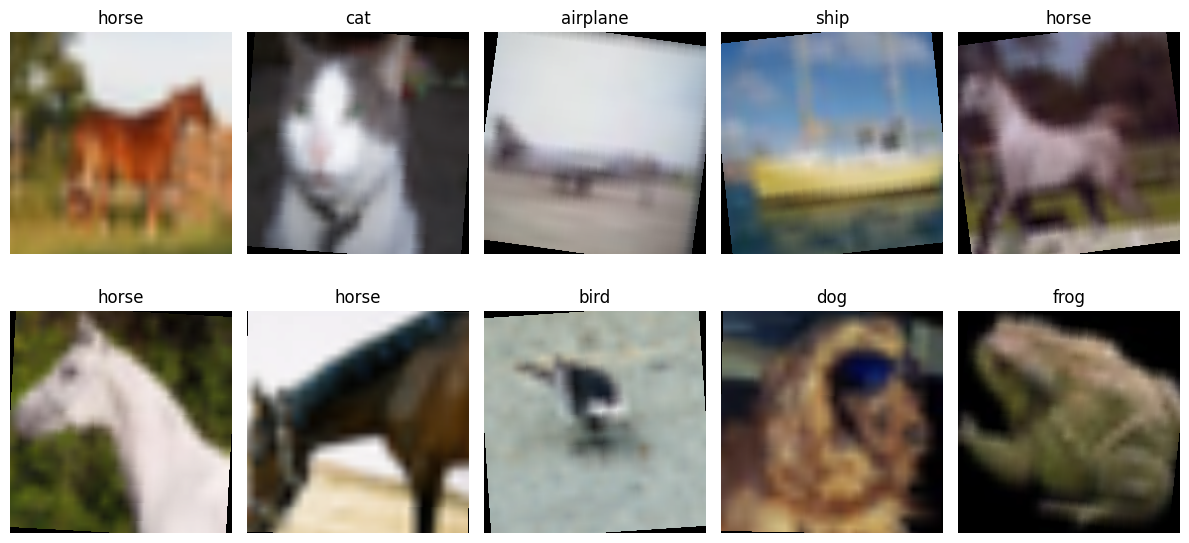

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))
for i in range(10):
    image = images[i].permute(1, 2, 0).numpy()
    image = image * np.array(std) + np.array(mean)
    image = np.clip(image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Load Pretrained EfficientNet-B0


In [ ]:
weights = EfficientNet_B0_Weights.DEFAULT
backbone = models.efficientnet_b0(weights=weights)

for param in backbone.features.parameters():
    param.requires_grad = False

num_features = backbone.classifier[1].in_features
print("Number of input features:", num_features)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]


Number of input features: 1280


## 8. Build the Model


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

backbone.classifier = nn.Identity()

model = nn.Sequential(
    backbone,
    nn.Linear(num_features, 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 10)
)

# He initialization for the hidden Dense layer
nn.init.kaiming_normal_(model[1].weight, nonlinearity="relu")
nn.init.zeros_(model[1].bias)

# Initialize output layer
nn.init.xavier_uniform_(model[5].weight)
nn.init.zeros_(model[5].bias)

model = model.to(device)
print(model)

Sequential(
  (0): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
       

## 9. Loss Function, Optimizer, and Scheduler

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Scheduler:", scheduler)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7c495c5412b0>


## 10. Training and Validation Functions

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, leave=False):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    return total_loss / total, 100 * correct / total


def validate_model(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    return total_loss / total, 100 * correct / total

## 11. Training Function with Early Stopping and Model Checkpoint


In [ ]:
def train_model(model, train_loader, val_loader, criterion,
                optimizer, scheduler, phase_name,
                max_epochs=30, min_epochs=20, patience=5):

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    wait = 0

    for epoch in range(max_epochs):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = validate_model(
            model, val_loader, criterion
        )

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, f"best_{phase_name}.pth")
            wait = 0
        else:
            wait += 1

        print(
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.2f}% | "
            f"Val loss: {val_loss:.4f} | Val acc: {val_acc:.2f}% | "
            f"Time: {time.time() - start_time:.1f}s"
        )

        if epoch + 1 >= min_epochs and wait >= patience:
            print("Early stopping")
            break

    model.load_state_dict(best_weights)
    return model, history

## 12. Feature Extraction Training


In [ ]:
model, history_feature = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    phase_name="feature_extraction",
    max_epochs=30,
    min_epochs=20,
    patience=5
)

  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 1/30 | Train loss: 1.0430 | Train acc: 64.47% | Val loss: 0.6172 | Val acc: 78.66% | Time: 123.5s


  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 2/30 | Train loss: 0.8485 | Train acc: 70.38% | Val loss: 0.5870 | Val acc: 80.08% | Time: 118.6s


  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 3/30 | Train loss: 0.8036 | Train acc: 71.98% | Val loss: 0.5603 | Val acc: 80.78% | Time: 115.1s


... (7 outputs left out)

Epoch 7/30 | Train loss: 0.7491 | Train acc: 73.80% | Val loss: 0.5331 | Val acc: 82.24% | Time: 117.4s


  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 8/30 | Train loss: 0.7384 | Train acc: 74.39% | Val loss: 0.5376 | Val acc: 81.66% | Time: 116.1s


  0%|          | 0/704 [00:00<?, ?it/s]

## 13. Plot Training and Validation Loss

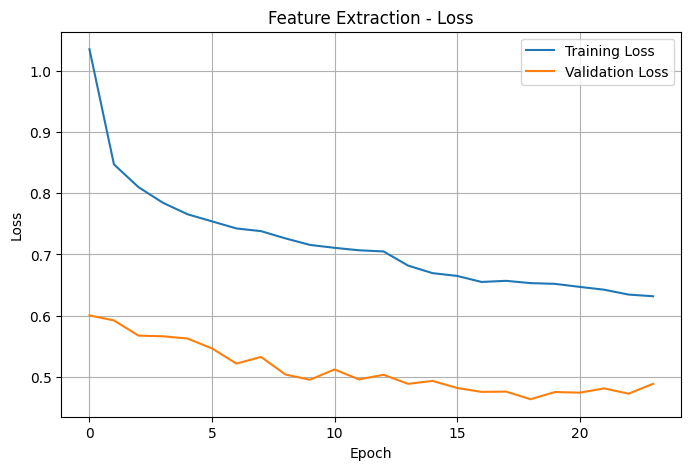

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history_feature["train_loss"], label="Training Loss")
plt.plot(history_feature["val_loss"], label="Validation Loss")
plt.title("Feature Extraction - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

## 14. Plot Training and Validation Accuracy

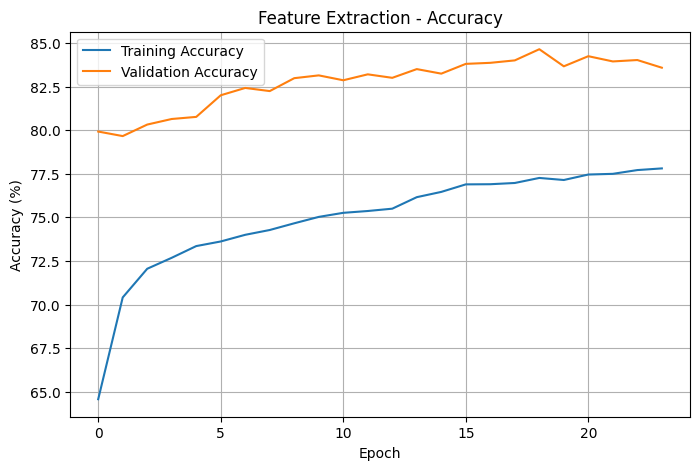

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history_feature["train_acc"], label="Training Accuracy")
plt.plot(history_feature["val_acc"], label="Validation Accuracy")
plt.title("Feature Extraction - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()
plt.show()

## 15. Fine-Tuning

In [ ]:
# Freeze all feature extraction layers
for param in model[0].features.parameters():
    param.requires_grad = False

# Unfreeze the final feature block
for param in model[0].features[-1].parameters():
    param.requires_grad = True

trainable_params = sum(
    param.numel() for param in model.parameters()
    if param.requires_grad
)
print("Trainable parameters:", trainable_params)

optimizer_finetune = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5,
    weight_decay=1e-4
)

scheduler_finetune = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_finetune, mode="min", factor=0.5, patience=2
)

Trainable parameters: 1074186


## 16. Train Fine-Tuned Model

In [ ]:
model, history_finetune = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer_finetune,
    scheduler_finetune,
    phase_name="fine_tuning",
    max_epochs=15,
    min_epochs=1,
    patience=5
)

  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 1/15 | Train loss: 0.6443 | Train acc: 77.55% | Val loss: 0.4776 | Val acc: 83.94% | Time: 115.4s


  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 2/15 | Train loss: 0.6343 | Train acc: 77.75% | Val loss: 0.4690 | Val acc: 84.08% | Time: 118.1s


  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 3/15 | Train loss: 0.6323 | Train acc: 78.03% | Val loss: 0.4647 | Val acc: 84.32% | Time: 116.6s


... (20 outputs left out)

  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 14/15 | Train loss: 0.5931 | Train acc: 79.32% | Val loss: 0.4289 | Val acc: 85.24% | Time: 118.1s


  0%|          | 0/704 [00:00<?, ?it/s]

Epoch 15/15 | Train loss: 0.5930 | Train acc: 79.46% | Val loss: 0.4275 | Val acc: 85.28% | Time: 118.0s



## 17. Fine-Tuning Loss and Accuracy Graphs

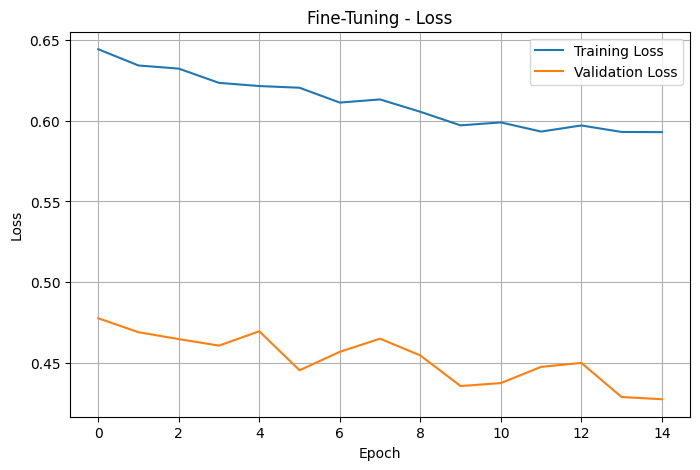

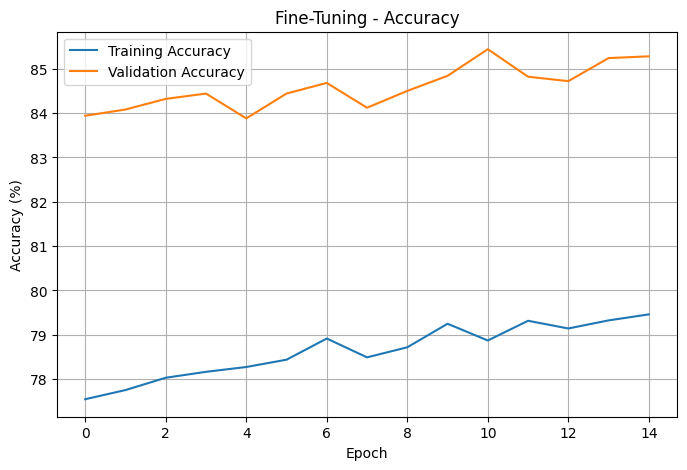

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history_finetune["train_loss"], label="Training Loss")
plt.plot(history_finetune["val_loss"], label="Validation Loss")
plt.title("Fine-Tuning - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_finetune["train_acc"], label="Training Accuracy")
plt.plot(history_finetune["val_acc"], label="Validation Accuracy")
plt.title("Fine-Tuning - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()
plt.show()

## 18. Compare Feature Extraction and Fine-Tuning

Feature Extraction Validation Accuracy: 84.64 %
Fine-Tuning Validation Accuracy: 85.44 %


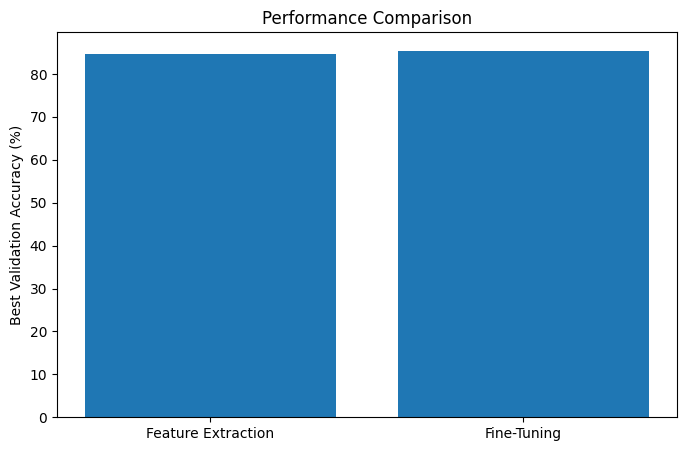

In [ ]:
feature_best_acc = max(history_feature["val_acc"])
finetune_best_acc = max(history_finetune["val_acc"])

print("Feature Extraction Validation Accuracy:", round(feature_best_acc, 2), "%")
print("Fine-Tuning Validation Accuracy:", round(finetune_best_acc, 2), "%")

plt.figure(figsize=(8, 5))
plt.bar(
    ["Feature Extraction", "Fine-Tuning"],
    [feature_best_acc, finetune_best_acc]
)
plt.ylabel("Best Validation Accuracy (%)")
plt.title("Performance Comparison")
plt.show()

## 19. Test Dataset Evaluation

In [ ]:
model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

test_accuracy = accuracy_score(all_labels, all_predictions)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

  0%|          | 0/157 [00:00<?, ?it/s]

Test Accuracy: 84.06 %


## 20. Confusion Matrix

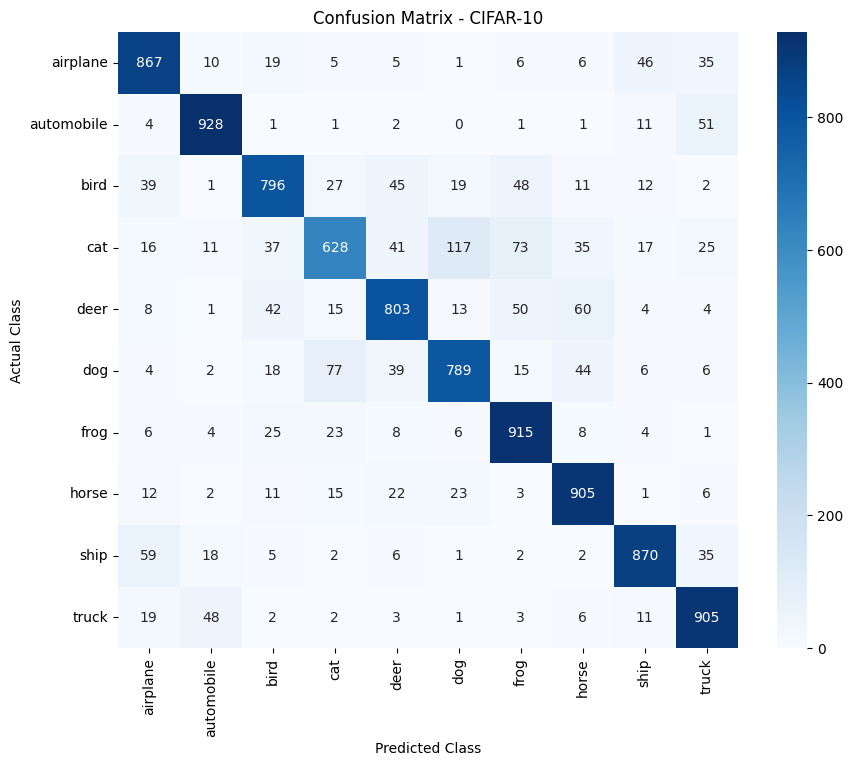

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("Confusion Matrix - CIFAR-10")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## 21. Classification Report

In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

    airplane     0.8385    0.8670    0.8525      1000
  automobile     0.9054    0.9280    0.9165      1000
        bird     0.8326    0.7960    0.8139      1000
         cat     0.7899    0.6280    0.6997      1000
        deer     0.8244    0.8030    0.8136      1000
         dog     0.8134    0.7890    0.8010      1000
        frog     0.8199    0.9150    0.8648      1000
       horse     0.8395    0.9050    0.8710      1000
        ship     0.8859    0.8700    0.8779      1000
       truck     0.8458    0.9050    0.8744      1000

    accuracy                         0.8406     10000
   macro avg     0.8395    0.8406    0.8385     10000
weighted avg     0.8395    0.8406    0.8385     10000



## 22. Per-Class Accuracy and Hardest Class

In [ ]:
class_correct = np.zeros(len(class_names))
class_total = np.zeros(len(class_names))

for actual, predicted in zip(all_labels, all_predictions):
    class_total[actual] += 1
    if actual == predicted:
        class_correct[actual] += 1

class_accuracy = 100 * class_correct / class_total

for i, name in enumerate(class_names):
    print(f"{name}: {class_accuracy[i]:.2f}%")

hardest_index = np.argmin(class_accuracy)
print("\nHardest class:", class_names[hardest_index])
print("Accuracy:", f"{class_accuracy[hardest_index]:.2f}%")

airplane: 86.70%
automobile: 92.80%
bird: 79.60%
cat: 62.80%
deer: 80.30%
dog: 78.90%
frog: 91.50%
horse: 90.50%
ship: 87.00%
truck: 90.50%

Hardest class: cat
Accuracy: 62.80%


## 23. Display Sample Predictions

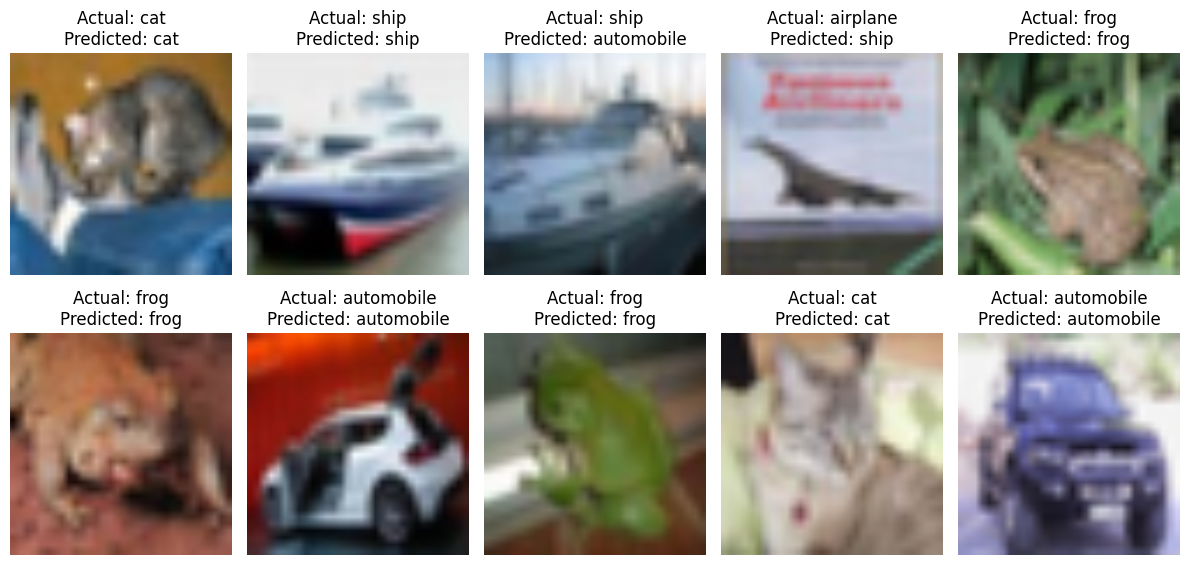

In [ ]:
images, labels = next(iter(test_loader))
model.eval()

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

plt.figure(figsize=(12, 6))
for i in range(10):
    image = images[i].permute(1, 2, 0).numpy()
    image = image * np.array(std) + np.array(mean)
    image = np.clip(image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {class_names[labels[i]]}\n"
        f"Predicted: {class_names[predictions[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 24. Save the Final Model and Class Names

In [ ]:
torch.save(model.state_dict(), "efficientnet_cifar10_final.pth")

with open("class_names.json", "w") as file:
    json.dump(class_names, file)

print("Model and class names saved successfully")

Model and class names saved successfully


## 25. Final Project Summary

In [ ]:
print("========== PROJECT SUMMARY ==========")
print("Dataset: CIFAR-10")
print("Model: EfficientNet-B0")
print("Framework: PyTorch")
print("Device:", device)
print("Feature Extraction Best Validation Accuracy:",
      f"{feature_best_acc:.2f}%")
print("Fine-Tuning Best Validation Accuracy:",
      f"{finetune_best_acc:.2f}%")
print("Test Accuracy:", f"{test_accuracy * 100:.2f}%")
print("======================================")

========== PROJECT SUMMARY ==========
Dataset: CIFAR-10
Model: EfficientNet-B0
Framework: PyTorch
Device: cuda
Feature Extraction Best Validation Accuracy: 84.64%
Fine-Tuning Best Validation Accuracy: 85.44%
Test Accuracy: 84.06%
